# 2.2 · LGD: continued synthetic pretraining

[Notebook index](../README.md)

Start from released TabICLv2 and TabPFN-3 weights. Cross four credit mixtures (0%, 25%, 50%, 100%),
two peak learning rates and three paired seeds: **48 runs per task, 96 total**, each with
10,000 optimizer updates. Backbones have different table/task budgets and are not compute-matched.
This notebook diagnoses optimization; full five-fold credit/OOD results belong to the results notebook.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "src" / "visualize").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from src.visualize import figures, style, campaign, continuation, paper_plots as paper, training_plots
from src.experiments import results
style.apply()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 80)
FIGS = figures.FigureSaver("2.2_lgd_finetuning")
TASK, EXP = "lgd", "exp2"

## A · Registered design and local coverage
The archive is a dated snapshot, not a live queue. The 0% mixture controls for extra training;
it does not guarantee that the released performance is retained.

LOCAL EVIDENCE — not a live scheduler query
Experiment 2, LGD; current benchmark protocol 9.
Local notebook-code fingerprint: 4b31d59be2048f41f894db9a26c49919f759e65e9fdfae4305dd52e27ae164d0.
Downloaded archive: output CreditICL.zip; local download time 2026-10-24 10:07:39 Europe/Brussels.
Archive SHA-256: ddddb3b064c7d971520bffb626b2e7c67cfbceb6b81fab5133992e4dd4453c0e
Recorded executable fingerprint: 20f0e98161f9e988b5eaf0d2775fb34406547844bafbbd90a653fb9bbe7e44c5
Latest training record in that snapshot: 2026-10-24 01:21:15 CEST.
Main comparison: 0/48 downloaded completions; 0 partial traces; 48 without local output.
Partial traces do not establish that a job is still running; absent output does not establish that it was never queued.
Final credit/OOD benchmarking is a separate completion gate; monitoring is not its substitute.
Backbone  Runs per track     Peak LRs  Weight decay  Updates Tables per run           Rows per table Context share Expected row exposures
TabICLv2            

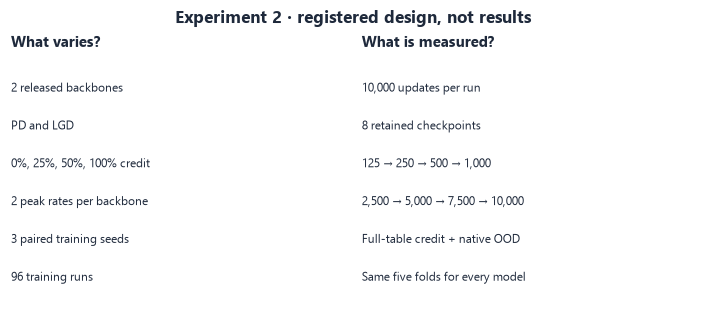

In [2]:
print(campaign.provenance(TASK, EXP))
print(campaign.continuation_recipe(TASK).to_string(index=False))
FIGS.save(continuation.design_figure(2), "registered_continuation_design",
    caption="Registered continuation design: two released backbones, two prediction tasks, four credit-prior mixtures, two learning rates per backbone and three training seeds; eight checkpoint evaluations use full eligible tables and shared five-fold splits.")
if campaign.coverage(TASK, EXP).state.ne("absent").any():
    for backbone in continuation.BACKBONES:
        FIGS.save(campaign.main_coverage(TASK, EXP, backbone=backbone), f"coverage_{backbone}",
            caption="Local training-record coverage by mixture, peak learning rate and seed for one backbone; completed and partial traces describe downloaded evidence, not live queue states.")

## B · Does optimization remain stable?
Separate backbones and learning rates. Thin traces are seeds; thick means require three seeds
at a common update. Different synthetic-task losses do not rank downstream quality.

In [3]:
if training_plots.load_loss_logs(TASK, EXP):
    for backbone in continuation.BACKBONES:
        FIGS.save(continuation.training_curves(TASK, backbone), f"loss_{backbone}",
            caption="Synthetic query loss against optimizer update, separated by backbone and peak learning rate; colors identify credit fractions, thin traces show seeds and thick curves average three seeds at common recorded steps.")
else:
    print("No local optimization traces yet.")

No local optimization traces yet.


## C · Development monitoring, distinct from full benchmarks
Small-context monitoring is diagnostic. It selects neither a mixture nor an early stopping
point. The primary endpoint remains 10,000 updates; full-table trajectories are separate.

In [4]:
if training_plots.load_progress(TASK, EXP):
    for backbone in continuation.BACKBONES:
        FIGS.save(continuation.training_curves(TASK, backbone, metric="roc_auc" if TASK == "pd" else "r2"),
            f"development_monitoring_{backbone}",
            caption="Development monitoring score against update for one backbone, with separate learning-rate panels and mixture colors; small-context diagnostics are distinct from the full-table five-fold benchmark.")
else:
    print("No local monitoring curves yet.")

No local monitoring curves yet.


## Summary
A: design and provenance; B: optimization; C: diagnostic monitoring.

In [5]:
print(campaign.training_summary(TASK, EXP))
print(FIGS.summary())

A · PROVENANCE AND RUN COVERAGE
LOCAL EVIDENCE — not a live scheduler query
Experiment 2, LGD; current benchmark protocol 9.
Local notebook-code fingerprint: 4b31d59be2048f41f894db9a26c49919f759e65e9fdfae4305dd52e27ae164d0.
Downloaded archive: output CreditICL.zip; local download time 2026-10-24 10:07:39 Europe/Brussels.
Archive SHA-256: ddddb3b064c7d971520bffb626b2e7c67cfbceb6b81fab5133992e4dd4453c0e
Recorded executable fingerprint: 20f0e98161f9e988b5eaf0d2775fb34406547844bafbbd90a653fb9bbe7e44c5
Latest training record in that snapshot: 2026-10-24 01:21:15 CEST.
Main comparison: 0/48 downloaded completions; 0 partial traces; 48 without local output.
Partial traces do not establish that a job is still running; absent output does not establish that it was never queued.
Final credit/OOD benchmarking is a separate completion gate; monitoring is not its substitute.
PLANNED CONTINUATION (not completed training)
Backbone  Runs per track     Peak LRs  Weight decay  Updates Tables per run     